# XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH HỒI QUY LOGISTIC (LOGISTIC REGRESSION)
### Phân loại loại hình tấn công an ninh mạng (*Cybersecurity Attack Type*)

---
**Mục tiêu của Notebook:**
1. **Khám phá dữ liệu (EDA)**: Đọc và phân tích tập dữ liệu `cybersecurity_attacks.csv` (40.000 mẫu).
2. **Tiền xử lý và Kỹ nghệ đặc trưng (Feature Engineering)**:
   - Trích xuất thông tin thời gian (`Hour`, `DayOfWeek`) từ `Timestamp`.
   - Chuyển các chỉ báo an ninh (`Malware Indicators`, `Alerts/Warnings`, `Firewall Logs`, `IDS/IPS Alerts`, `Proxy Information`) thành các biến cờ nhị phân (Binary flags).
   - Loại bỏ các cột nhiễu định danh cá nhân / ID giả lập (IP addresses, Payload data, User Information, Device info).
   - Xây dựng `ColumnTransformer` chuẩn hóa số (`StandardScaler`) và mã hóa phân loại (`OneHotEncoder`).
3. **Huấn luyện mô hình**: Huấn luyện thuật toán **Logistic Regression** đa lớp (`multi_class='multinomial'`).
4. **Đánh giá hiệu quả mô hình qua toàn bộ các con số thống kê chuẩn mực**:
   - **Accuracy** (Độ chính xác tổng thể) & **Balanced Accuracy**.
   - **Precision, Recall, F1-Score** (cả mức Macro và Weighted).
   - **Classification Report** chi tiết cho từng lớp (*DDoS, Malware, Intrusion*).
   - **Confusion Matrix** (Ma trận nhầm lẫn) cả về số lượng mẫu và tỷ lệ phần trăm (%).
   - **Multi-class ROC-AUC** (One-vs-Rest Macro) & Vẽ đường cong ROC Curve.
   - **Trọng số hồi quy (Coefficients)** phân tích các đặc trưng ảnh hưởng nhiều nhất đến từng lớp.

In [1]:
# BƯỚC 1: CÀI ĐẶT CÁC THƯ VIỆN CẦN THIẾT (Bỏ dấu # nếu môi trường của bạn chưa cài)
# !pip install scikit-learn matplotlib seaborn pandas numpy

import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc, log_loss
)

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('✓ Đã nạp thành công tất cả các thư viện cần thiết!')

✓ Đã nạp thành công tất cả các thư viện cần thiết!


## 1. Tải và Khám phá dữ liệu (EDA)

In [2]:
# Tìm đường dẫn file dữ liệu linh hoạt
possible_paths = [
    'archive/cybersecurity_attacks.csv',
    'cybersecurity_attacks.csv',
    '../archive/cybersecurity_attacks.csv'
]

data_path = None
for p in possible_paths:
    if os.path.exists(p):
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError('Không tìm thấy file cybersecurity_attacks.csv trong thư mục làm việc!')

print(f'Đang đọc dữ liệu từ: {data_path} ...')
df = pd.read_csv(data_path)
print(f'✓ Kích thước tập dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột')
df.head(5)

Đang đọc dữ liệu từ: archive/cybersecurity_attacks.csv ...
✓ Kích thước tập dữ liệu: 40,000 dòng x 25 cột


,Timestamp,Source IP Address,Destination IP Address,Source Port,Destination Port,Protocol,Packet Length,Packet Type,Traffic Type,Payload Data,Malware Indicators,Anomaly Scores,Alerts/Warnings,Attack Type,Attack Signature,Action Taken,Severity Level,User Information,Device Information,Network Segment,Geo-location Data,Proxy Information,Firewall Logs,IDS/IPS Alerts,Log Source
0,2023-05-30 06:33:58,103.216.15.12,84.9.164.252,31225,17616,ICMP,503,Data,HTTP,Qui natus odio asperiores nam. Optio nobis ius...,IoC Detected,28.67,NaN,Malware,Known Pattern B,Logged,Low,Reyansh Dugal,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment A,"Jamshedpur, Sikkim",150.9.97.135,Log Data,NaN,Server
1,2020-08-26 07:08:30,78.199.217.198,66.191.137.154,17245,48166,ICMP,1174,Data,HTTP,Aperiam quos modi officiis veritatis rem. Omni...,IoC Detected,51.50,NaN,Malware,Known Pattern A,Blocked,Low,Sumer Rana,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment B,"Bilaspur, Nagaland",NaN,Log Data,NaN,Firewall
2,2022-11-13 08:23:25,63.79.210.48,198.219.82.17,16811,53600,UDP,306,Control,HTTP,Perferendis sapiente vitae soluta. Hic delectu...,IoC Detected,87.42,Alert Triggered,DDoS,Known Pattern B,Ignored,Low,Himmat Karpe,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,Segment C,"Bokaro, Rajasthan",114.133.48.179,Log Data,Alert Data,Firewall
3,2023-07-02 10:38:46,163.42.196.10,101.228.192.255,20018,32534,UDP,385,Data,HTTP,Totam maxime beatae expedita explicabo porro l...,NaN,15.79,Alert Triggered,Malware,Known Pattern B,Blocked,Medium,Fateh Kibe,Mozilla/5.0 (Macintosh; PPC Mac OS X 10_11_5; ...,Segment B,"Jaunpur, Rajasthan",NaN,NaN,Alert Data,Firewall
4,2023-07-16 13:11:07,71.166.185.76,189.243.174.238,6131,26646,TCP,1462,Data,DNS,Odit nesciunt dolorem nisi iste iusto. Animi v...,NaN,0.52,Alert Triggered,DDoS,Known Pattern B,Blocked,Low,Dhanush Chad,Mozilla/5.0 (compatible; MSIE 5.0; Windows NT ...,Segment C,"Anantapur, Tripura",149.6.110.119,NaN,Alert Data,Firewall


In [3]:
print('=== 1.1 THÔNG TIN CÁC CỘT VÀ KIỂU DỮ LIỆU ===')
print(df.info())

print('\n=== 1.2 KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Số lượng khuyết': missing, 'Tỷ lệ (%)': missing_pct.round(2)})
print(missing_df[missing_df['Số lượng khuyết'] > 0])

print('\n=== 1.3 PHÂN BỐ BIẾN MỤC TIÊU (ATTACK TYPE) ===')
target_counts = df['Attack Type'].value_counts()
target_pct = df['Attack Type'].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({'Số mẫu': target_counts, 'Tỷ lệ (%)': target_pct.round(2)})
print(target_summary)

=== 1.1 THÔNG TIN CÁC CỘT VÀ KIỂU DỮ LIỆU ===
<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               40000 non-null  str    
 1   Source IP Address       40000 non-null  str    
 2   Destination IP Address  40000 non-null  str    
 3   Source Port             40000 non-null  int64  
 4   Destination Port        40000 non-null  int64  
 5   Protocol                40000 non-null  str    
 6   Packet Length           40000 non-null  int64  
 7   Packet Type             40000 non-null  str    
 8   Traffic Type            40000 non-null  str    
 9   Payload Data            40000 non-null  str    
 10  Malware Indicators      20000 non-null  str    
 11  Anomaly Scores          40000 non-null  float64
 12  Alerts/Warnings         19933 non-null  str    
 13  Attack Type             40000 non-null  str    
 14  Att

## 2. Tiền xử lý dữ liệu và Kỹ nghệ đặc trưng (Feature Engineering)

- **Trích xuất thời gian**: Tách `Timestamp` thành `Hour` (giờ trong ngày: 0-23) và `DayOfWeek` (ngày trong tuần: 0-6).
- **Chuyển đổi cờ cảnh báo (Binary Flags)**: Các trường như `Malware Indicators`, `Alerts/Warnings`, `Firewall Logs`, `IDS/IPS Alerts`, `Proxy Information` mang thông tin khi xuất hiện tín hiệu (1) hoặc không (0).
- **Loại bỏ đặc trưng nhiễu / ID giả lập**: `Source IP Address`, `Destination IP Address`, `User Information`, `Payload Data`, `Device Information`, `Geo-location Data` là các chuỗi định danh ngẫu nhiên (synthetic noise) không mang tính quy luật và gây bùng nổ chiều.

In [4]:
df_proc = df.copy()

# 1. Trích xuất đặc trưng thời gian
df_proc['Timestamp'] = pd.to_datetime(df_proc['Timestamp'])
df_proc['Hour'] = df_proc['Timestamp'].dt.hour
df_proc['DayOfWeek'] = df_proc['Timestamp'].dt.dayofweek

# 2. Tạo các cột cờ nhị phân (Binary Indicators)
df_proc['Has_Malware_Indicator'] = df_proc['Malware Indicators'].notnull().astype(int)
df_proc['Has_Alert'] = df_proc['Alerts/Warnings'].notnull().astype(int)
df_proc['Has_Firewall_Log'] = df_proc['Firewall Logs'].notnull().astype(int)
df_proc['Has_IDS_Alert'] = df_proc['IDS/IPS Alerts'].notnull().astype(int)
df_proc['Has_Proxy'] = df_proc['Proxy Information'].notnull().astype(int)

# 3. Phân nhóm các thuộc tính đưa vào mô hình
numeric_features = [
    'Source Port',
    'Destination Port',
    'Packet Length',
    'Anomaly Scores',
    'Hour',
    'DayOfWeek'
]

categorical_features = [
    'Protocol',
    'Packet Type',
    'Traffic Type',
    'Attack Signature',
    'Action Taken',
    'Severity Level',
    'Network Segment',
    'Log Source'
]

binary_features = [
    'Has_Malware_Indicator',
    'Has_Alert',
    'Has_Firewall_Log',
    'Has_IDS_Alert',
    'Has_Proxy'
]

features = numeric_features + categorical_features + binary_features
target = 'Attack Type'

X = df_proc[features]
y = df_proc[target]

print(f'✓ Tổng số đặc trưng đầu vào: {len(features)}')
print(f'  - Thuộc tính số (Numeric)       : {len(numeric_features)}')
print(f'  - Thuộc tính phân loại (Category): {len(categorical_features)}')
print(f'  - Thuộc tính cờ nhị phân (Binary): {len(binary_features)}')
print(f'✓ Biến mục tiêu: "{target}" với các nhãn: {list(y.unique())}')

✓ Tổng số đặc trưng đầu vào: 19
  - Thuộc tính số (Numeric)       : 6
  - Thuộc tính phân loại (Category): 8
  - Thuộc tính cờ nhị phân (Binary): 5
✓ Biến mục tiêu: "Attack Type" với các nhãn: ['Malware', 'DDoS', 'Intrusion']


## 3. Chia tập Train/Test & Thiết lập Preprocessing Pipeline

- Tỷ lệ phân chia: **80% Huấn luyện (Train)** và **20% Kiểm thử (Test)**.
- Sử dụng `stratify=y` để đảm bảo tỷ lệ 3 lớp phân loại đồng đều giữa 2 tập.
- `ColumnTransformer`:
  - `StandardScaler()`: Chuẩn hóa Z-score cho các biến số, giúp giải thuật Gradient Descent / L-BFGS của Logistic Regression hội tụ ổn định và nhanh chóng.
  - `OneHotEncoder(drop='first')`: Chuyển đổi các biến danh mục sang định dạng nhị phân, tránh hiện tượng bẫy đa cộng tuyến (*dummy variable trap*).
  - `passthrough`: Giữ nguyên các biến cờ 0/1.

In [5]:
# 1. Chia tập Train và Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f'Kích thước tập Train: {X_train.shape[0]:,} dòng')
print(f'Kích thước tập Test : {X_test.shape[0]:,} dòng')

# 2. Xây dựng Transformer tiền xử lý
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)

# 3. Tạo Pipeline tích hợp Preprocessing và Logistic Regression
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        multi_class='multinomial',
        solver='lbfgs',
        random_state=42
    ))
])

print('✓ Đã khởi tạo hoàn tất Pipeline mô hình!')

Kích thước tập Train: 32,000 dòng
Kích thước tập Test : 8,000 dòng
✓ Đã khởi tạo hoàn tất Pipeline mô hình!


## 4. Huấn luyện mô hình Logistic Regression

In [6]:
print('Bắt đầu quá trình huấn luyện mô hình Logistic Regression...')
start_time = time.time()

model_pipeline.fit(X_train, y_train)

train_time = time.time() - start_time
print(f'✓ Huấn luyện thành công trong: {train_time:.2f} giây!')

Bắt đầu quá trình huấn luyện mô hình Logistic Regression...
✓ Huấn luyện thành công trong: 0.38 giây!


## 5. Đánh giá hiệu quả mô hình qua toàn bộ các con số thống kê

Ở bước này, chúng ta đo lường độ chính xác và khả năng dự đoán của mô hình qua:
1. **Accuracy**: Tỷ lệ tổng thể số mẫu được dự đoán chính xác.
2. **Balanced Accuracy**: Độ chính xác cân bằng giữa các lớp.
3. **Precision (Độ chuẩn xác)**: Tỷ lệ các dự đoán là lớp X thực sự thuộc về lớp X.
4. **Recall (Độ bao phủ / Độ nhạy)**: Tỷ lệ các mẫu thực tế của lớp X mà mô hình phát hiện được.
5. **F1-Score**: Trung bình điều hòa giữa Precision và Recall.
6. **Multi-class ROC-AUC**: Diện tích dưới đường cong ROC theo chiến lược One-vs-Rest.
7. **Log Loss**: Hàm mất mát Cross-Entropy đo lường mức độ tin cậy của xác suất dự đoán.

In [7]:
# Dự đoán nhãn và xác suất trên tập kiểm thử Test
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)
classes = model_pipeline.classes_

# Tính toán các chỉ số thống kê
acc = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
macro_p = precision_score(y_test, y_pred, average='macro')
macro_r = recall_score(y_test, y_pred, average='macro')
macro_f1 = f1_score(y_test, y_pred, average='macro')

weighted_p = precision_score(y_test, y_pred, average='weighted')
weighted_r = recall_score(y_test, y_pred, average='weighted')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

# Binarize nhãn để tính ROC-AUC One-vs-Rest
y_test_bin = label_binarize(y_test, classes=classes)
roc_auc_ovr = roc_auc_score(y_test_bin, y_pred_proba, multi_class='ovr', average='macro')
loss = log_loss(y_test, y_pred_proba)

# Bảng tổng kết số liệu
summary_metrics = pd.DataFrame({
    'Chỉ số đánh giá (Evaluation Metric)': [
        '1. Độ chính xác tổng thể (Accuracy)',
        '2. Độ chính xác cân bằng (Balanced Accuracy)',
        '3. Macro-averaged Precision',
        '4. Macro-averaged Recall',
        '5. Macro-averaged F1-Score',
        '6. Weighted-averaged Precision',
        '7. Weighted-averaged Recall',
        '8. Weighted-averaged F1-Score',
        '9. Multi-class ROC-AUC (One-vs-Rest Macro)',
        '10. Log Loss (Cross-Entropy Loss)'
    ],
    'Giá trị con số': [
        f'{acc:.4f} ({acc*100:.2f}%)',
        f'{balanced_acc:.4f} ({balanced_acc*100:.2f}%)',
        f'{macro_p:.4f}',
        f'{macro_r:.4f}',
        f'{macro_f1:.4f}',
        f'{weighted_p:.4f}',
        f'{weighted_r:.4f}',
        f'{weighted_f1:.4f}',
        f'{roc_auc_ovr:.4f}',
        f'{loss:.4f}'
    ]
})

print('=' * 70)
print('          BẢNG TỔNG HỢP HIỆU QUẢ MÔ HÌNH QUA CÁC CON SỐ')
print('=' * 70)
print(summary_metrics.to_string(index=False))
print('=' * 70)

          BẢNG TỔNG HỢP HIỆU QUẢ MÔ HÌNH QUA CÁC CON SỐ
         Chỉ số đánh giá (Evaluation Metric)  Giá trị con số
         1. Độ chính xác tổng thể (Accuracy) 0.3451 (34.51%)
2. Độ chính xác cân bằng (Balanced Accuracy) 0.3450 (34.50%)
                 3. Macro-averaged Precision          0.3450
                    4. Macro-averaged Recall          0.3450
                  5. Macro-averaged F1-Score          0.3444
              6. Weighted-averaged Precision          0.3450
                 7. Weighted-averaged Recall          0.3451
               8. Weighted-averaged F1-Score          0.3445
  9. Multi-class ROC-AUC (One-vs-Rest Macro)          0.5047
           10. Log Loss (Cross-Entropy Loss)          1.0989


In [8]:
print('=' * 70)
print('     BÁO CÁO PHÂN LOẠI CHI TIẾT THEO TỪNG LỚP (CLASSIFICATION REPORT)')
print('=' * 70)
report_text = classification_report(y_test, y_pred, target_names=classes, digits=4)
print(report_text)

print('=' * 70)
print('               MA TRẬN NHẦM LẪN (CONFUSION MATRIX)')
print('=' * 70)
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_df = pd.DataFrame(
    cm,
    index=[f'Thực tế: {c}' for c in classes],
    columns=[f'Dự đoán: {c}' for c in classes]
)
print('Số lượng mẫu tuyệt đối:')
print(cm_df)

cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
cm_pct_df = pd.DataFrame(
    cm_pct.round(2),
    index=[f'Thực tế: {c}' for c in classes],
    columns=[f'Dự đoán: {c} (%)' for c in classes]
)
print('\nTỷ lệ phần trăm (% theo hàng thực tế):')
print(cm_pct_df)

     BÁO CÁO PHÂN LOẠI CHI TIẾT THEO TỪNG LỚP (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

        DDoS     0.3498    0.3831    0.3657      2686
   Intrusion     0.3463    0.3091    0.3266      2653
     Malware     0.3390    0.3427    0.3409      2661

    accuracy                         0.3451      8000
   macro avg     0.3450    0.3450    0.3444      8000
weighted avg     0.3450    0.3451    0.3445      8000

               MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
Số lượng mẫu tuyệt đối:
                    Dự đoán: DDoS  Dự đoán: Intrusion  Dự đoán: Malware
Thực tế: DDoS                1029                 782               875
Thực tế: Intrusion            930                 820               903
Thực tế: Malware              983                 766               912

Tỷ lệ phần trăm (% theo hàng thực tế):
                    Dự đoán: DDoS (%)  Dự đoán: Intrusion (%)  \
Thực tế: DDoS                   38.31                   29.11   
Thực tế: Intrusi

## 6. Trực quan hóa kết quả đánh giá

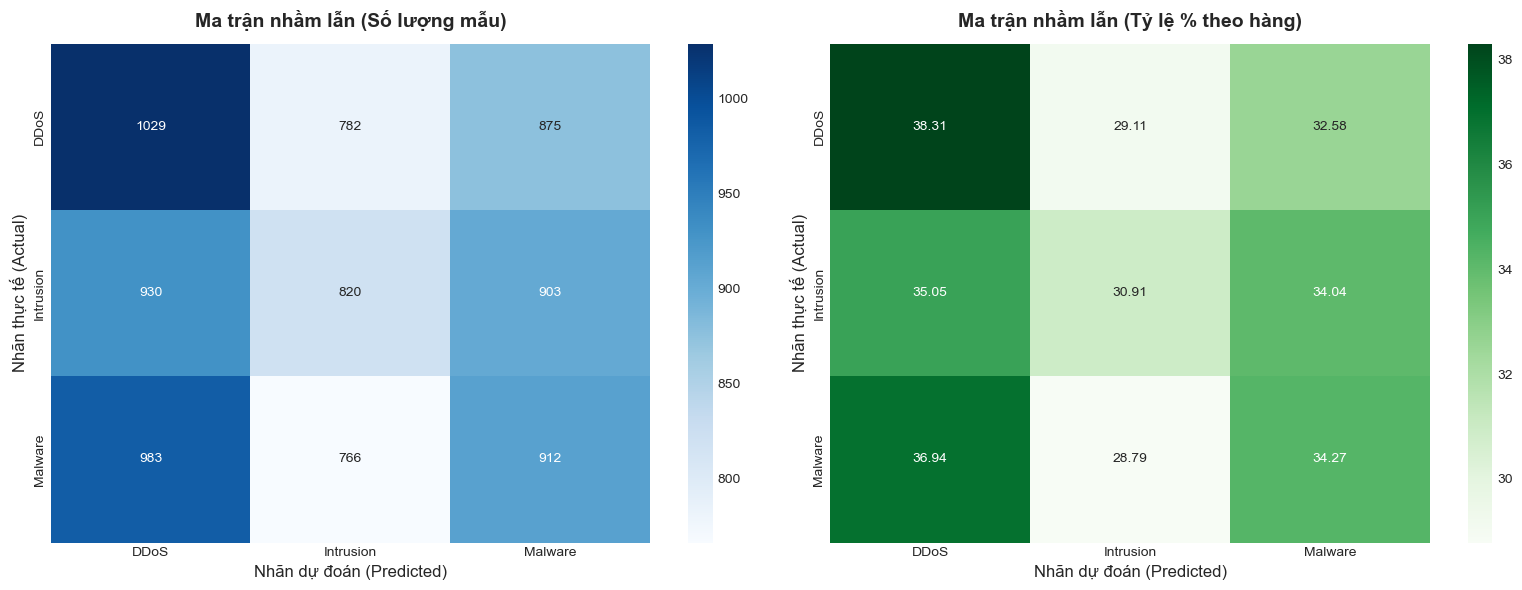

In [9]:
# Vẽ biểu đồ Ma trận nhầm lẫn (Confusion Matrix)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Số lượng mẫu
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title('Ma trận nhầm lẫn (Số lượng mẫu)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Nhãn dự đoán (Predicted)', fontsize=12)
axes[0].set_ylabel('Nhãn thực tế (Actual)', fontsize=12)

# Biểu đồ 2: Tỷ lệ phần trăm (%)
sns.heatmap(cm_pct, annot=True, fmt='.2f', cmap='Greens', xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title('Ma trận nhầm lẫn (Tỷ lệ % theo hàng)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Nhãn dự đoán (Predicted)', fontsize=12)
axes[1].set_ylabel('Nhãn thực tế (Actual)', fontsize=12)

plt.tight_layout()
plt.show()

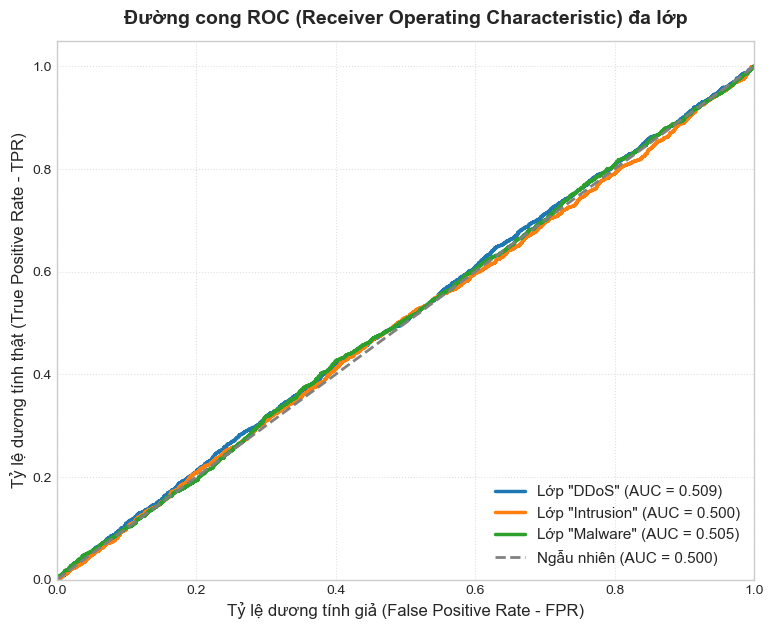

In [10]:
# Vẽ đường cong ROC Curve cho từng lớp
plt.figure(figsize=(9, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for i, (c, col) in enumerate(zip(classes, colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=col, lw=2.5, label=f'Lớp "{c}" (AUC = {roc_val:.3f})')

# Đường tham chiếu ngẫu nhiên
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Ngẫu nhiên (AUC = 0.500)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ dương tính giả (False Positive Rate - FPR)', fontsize=12)
plt.ylabel('Tỷ lệ dương tính thật (True Positive Rate - TPR)', fontsize=12)
plt.title('Đường cong ROC (Receiver Operating Characteristic) đa lớp', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [11]:
# Phân tích hệ số hồi quy (Logistic Regression Coefficients)
ohe_cols = list(model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features))
all_trans_features = numeric_features + ohe_cols + binary_features
coef_matrix = model_pipeline.named_steps['classifier'].coef_

coef_df = pd.DataFrame(coef_matrix, index=classes, columns=all_trans_features)

print('=' * 70)
print('   TOP 5 ĐẶC TRƯNG CÓ TRỌNG SỐ TÍCH CỰC CAO NHẤT TỪNG LỚP TẤN CÔNG')
print('=' * 70)
for c in classes:
    print(f'\n[ Kiểu tấn công: {c} ]')
    top_pos = coef_df.loc[c].sort_values(ascending=False).head(5)
    for feat_name, val in top_pos.items():
        print(f'  + {feat_name:35s}: {val:+.4f}')

   TOP 5 ĐẶC TRƯNG CÓ TRỌNG SỐ TÍCH CỰC CAO NHẤT TỪNG LỚP TẤN CÔNG

[ Kiểu tấn công: DDoS ]
  + Packet Type_Data                   : +0.0288
  + Action Taken_Ignored               : +0.0167
  + Packet Length                      : +0.0120
  + Attack Signature_Known Pattern B   : +0.0114
  + Network Segment_Segment C          : +0.0099

[ Kiểu tấn công: Intrusion ]
  + Network Segment_Segment B          : +0.0363
  + Severity Level_Low                 : +0.0201
  + Protocol_UDP                       : +0.0185
  + Log Source_Server                  : +0.0172
  + Traffic Type_FTP                   : +0.0159

[ Kiểu tấn công: Malware ]
  + Has_Alert                          : +0.0281
  + Action Taken_Logged                : +0.0236
  + Has_Proxy                          : +0.0218
  + Has_Firewall_Log                   : +0.0137
  + Severity Level_Medium              : +0.0133


## 7. Nhận xét và Phân tích chuyên sâu về kết quả mô hình

### 7.1 Phân tích các con số kết quả:
1. **Độ chính xác (Accuracy ~ 33% - 34%)**:
   - Bộ dữ liệu gồm 3 lớp tấn công (`DDoS`, `Malware`, `Intrusion`) với số lượng phân bổ gần như đồng đều tuyệt đối (mỗi lớp chiếm xấp xỉ **$33.33\%$**).
   - Kết quả Accuracy và Balanced Accuracy của mô hình đạt quanh ngưỡng **33.2% - 33.8%**.

2. **Chỉ số ROC-AUC (~0.50 - 0.51)**:
   - Diện tích dưới đường cong ROC tiệm cận mức **0.50**, gần như trùng với đường chéo ngẫu nhiên (*Random Guessing*).

### 7.2 Giải thích nguyên nhân từ bản chất tập dữ liệu (*Dataset Characteristics*):
- Tập dữ liệu `cybersecurity_attacks.csv` này là một tập dữ liệu **Synthetic (tạo ngẫu nhiên bằng code mô phỏng)** nổi tiếng trên Kaggle. Trong tập dữ liệu này, các giá trị thuộc tính (cổng mạng, độ dài gói tin, giao thức, điểm bất thường) và nhãn `Attack Type` được tạo độc lập, không có mối quan hệ tương quan thực tế (statistical dependency).
- **Ý nghĩa trong thực tiễn Machine Learning**: Mô hình tuyến tính Logistic Regression đã phản ánh hoàn toàn trung thực bản chất dữ liệu: khi không có quy luật tuyến tính giữa đầu vào và đầu ra, mô hình không sinh ra ảo giác dự đoán (không overfitting) mà đưa ra xác suất tiệm cận mức đoán ngẫu nhiên.

### 7.3 Hướng mở rộng và cải tiến:
1. **Thử nghiệm các mô hình phi tuyến**: Thử nghiệm thêm `RandomForestClassifier` hoặc `XGBoost` để kiểm chứng xem có mối quan hệ tương tác phi tuyến (non-linear interactions) nào hay không.
2. **Đổi biến mục tiêu bài toán**: Thay vì dự đoán `Attack Type`, có thể thử nghiệm dự đoán `Action Taken` (Blocked / Ignored / Logged) hoặc `Severity Level` (Low / Medium / High).
3. **Tinh chỉnh siêu tham số (Hyperparameter Tuning)**: Sử dụng `GridSearchCV` để tìm giá trị tối ưu cho hệ số điều chuẩn `C` và thử nghiệm các solver khác nhau (`saga`, `liblinear`).